In [23]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import seaborn as sns
from kedro.config import OmegaConfigLoader
from kedro.io import DataCatalog

warnings.filterwarnings("ignore", message=".*register_new_resolver.*")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(raiz)
config = OmegaConfigLoader(conf_source="conf", base_env="base", default_run_env="local")
catalog = DataCatalog.from_config(config["catalog"])

CARPETA_FIGURAS = Path("docs/figuras")
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
# Las figuras pueden estar en data/08_reporting (entorno local) o en
# data/ci/08_reporting (entorno ci). Se busca en ambos.
CARPETAS_REPORTES = [Path("data/08_reporting"), Path("data/ci/08_reporting")]
AZUL, ROJO, GRIS = "#4C72B0", "#C44E52", "#8C8C8C"


def guardar(fig: plt.Figure, nombre: str) -> None:
    """Guarda una figura del reporte en docs/figuras."""
    fig.savefig(CARPETA_FIGURAS / f"{nombre}.png", dpi=200, bbox_inches="tight")


def mostrar_png(nombre_archivo: str) -> None:
    """Muestra una figura PNG generada por kedro run."""
    ruta = next(
        (
            c / nombre_archivo
            for c in CARPETAS_REPORTES
            if (c / nombre_archivo).exists()
        ),
        None,
    )
    if ruta is None:
        raise FileNotFoundError(
            f"No se encontró {nombre_archivo} en {CARPETAS_REPORTES}"
        )
    img = mpimg.imread(ruta)
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [24]:
# Cargar datos del catálogo
model_metrics = catalog.load("model_metrics")
model_selection = catalog.load("model_selection")
feature_importance = catalog.load("feature_importance")
seller_summary = catalog.load("seller_summary")
sales_insights = catalog.load("sales_insights")
business_impact = catalog.load("business_impact")
best_params = catalog.load("best_params")
optuna_trials = catalog.load("optuna_trials")
test_predictions = catalog.load("test_predictions")
model_input_test = catalog.load("model_input_test")

---

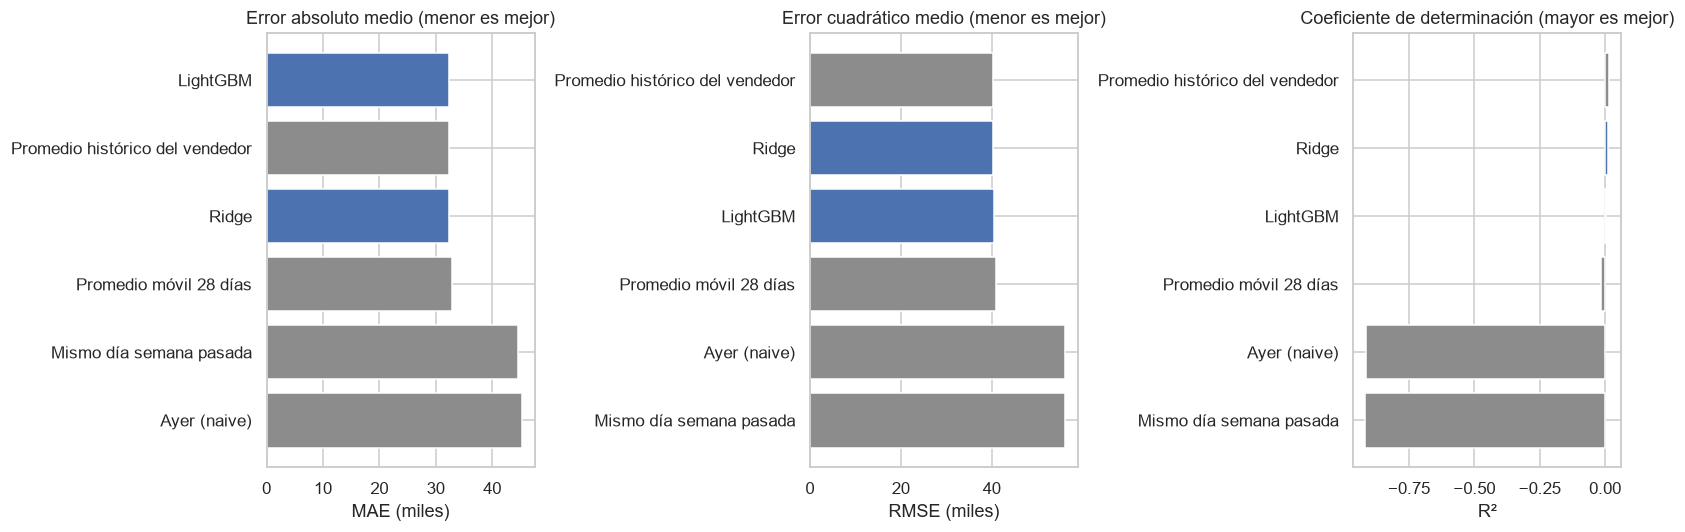

In [25]:
# Preparar datos para visualización
metricas_vis = model_metrics.copy()
metricas_vis["model"] = metricas_vis["model"].str.replace(
    "Línea base", "Base", regex=False
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# MAE
ax = axes[0]
data = metricas_vis.sort_values("MAE")
colors = [AZUL if t == "Modelo ML" else GRIS for t in data["type"]]
ax.barh(data["model"], data["MAE"] / 1e3, color=colors)
ax.set_xlabel("MAE (miles)")
ax.set_title("Error absoluto medio (menor es mejor)")
ax.invert_yaxis()

# RMSE
ax = axes[1]
data = metricas_vis.sort_values("RMSE")
colors = [AZUL if t == "Modelo ML" else GRIS for t in data["type"]]
ax.barh(data["model"], data["RMSE"] / 1e3, color=colors)
ax.set_xlabel("RMSE (miles)")
ax.set_title("Error cuadrático medio (menor es mejor)")
ax.invert_yaxis()

# R²
ax = axes[2]
data = metricas_vis.sort_values("R2", ascending=False)
colors = [AZUL if t == "Modelo ML" else GRIS for t in data["type"]]
ax.barh(data["model"], data["R2"], color=colors)
ax.set_xlabel("R²")
ax.set_title("Coeficiente de determinación (mayor es mejor)")
ax.invert_yaxis()

plt.tight_layout()
guardar(fig, "1_comparacion_modelos")
plt.show()

In [26]:
# Mostrar tabla de métricas
print("Métricas de modelos:")
print(model_metrics.to_string(index=False))

Métricas de modelos:
                          model       type          MAE         RMSE   MAPE_%        R2  improvement_vs_best_baseline_%
                       LightGBM  Modelo ML 32276.885698 40468.672485 2.234079  0.005069                        0.104119
Promedio histórico del vendedor Línea base 32310.527233 40249.845521 2.235051  0.015800                        0.000000
                          Ridge  Modelo ML 32416.813524 40317.549238 2.245365  0.012486                       -0.328953
         Promedio móvil 28 días Línea base 32789.004052 40866.303055 2.267863 -0.014579                       -1.480870
        Mismo día semana pasada Línea base 44616.403669 56162.494474 3.087984 -0.916231                      -38.086276
                   Ayer (naive) Línea base 45253.130651 56127.807567 3.129024 -0.913864                      -40.056924


---

In [27]:
print(f"Modelo seleccionado: {model_selection['selected_model']}")
print(
    f"Mejor línea base: {model_selection['best_baseline']} (MAE: {model_selection['best_baseline_mae']:,.2f})"
)
print(
    f"Mejor modelo ML: {model_selection['best_ml_model']} (MAE: {model_selection['best_ml_mae']:,.2f})"
)
print(f"Mejora ML vs baseline: {model_selection['ml_improvement_%']:.2f}%")
print(f"Umbral requerido: {model_selection['min_improvement_%']:.0f}%")

Modelo seleccionado: Promedio histórico del vendedor
Mejor línea base: Promedio histórico del vendedor (MAE: 32,310.53)
Mejor modelo ML: LightGBM (MAE: 32,276.89)
Mejora ML vs baseline: 0.10%
Umbral requerido: 2%


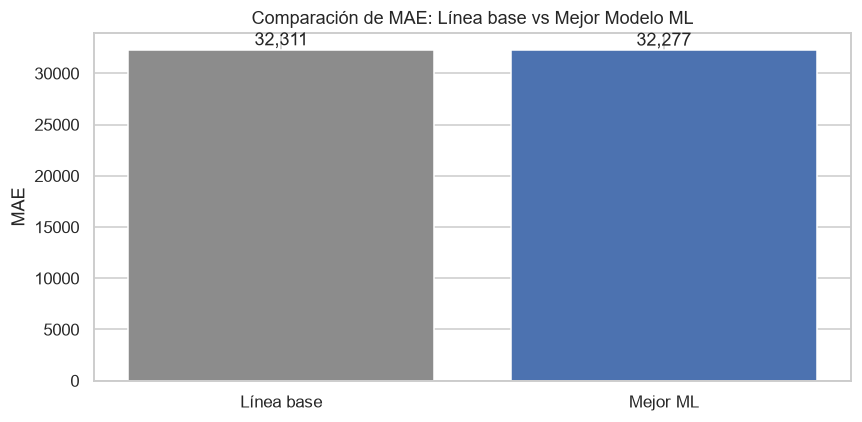

In [28]:
# Visualizar mejora
fig, ax = plt.subplots(figsize=(8, 4))
models = ["Línea base", "Mejor ML"]
maes = [model_selection["best_baseline_mae"], model_selection["best_ml_mae"]]
colors = [GRIS, AZUL]
bars = ax.bar(models, maes, color=colors)
ax.set_ylabel("MAE")
ax.set_title("Comparación de MAE: Línea base vs Mejor Modelo ML")
for bar, mae in zip(bars, maes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{mae:,.0f}",
        ha="center",
        va="bottom",
    )
plt.tight_layout()
guardar(fig, "2_seleccion_modelo")
plt.show()

---

In [29]:
print("Mejores hiperparámetros:")
print(json.dumps(best_params, indent=2))

Mejores hiperparámetros:
{
  "ridge": {
    "params": {
      "alpha": 1678.5981642266354
    },
    "cv_mae": 34273.24169393231
  },
  "lightgbm": {
    "params": {
      "n_estimators": 131,
      "learning_rate": 0.01714872694149244,
      "num_leaves": 11,
      "min_child_samples": 99,
      "subsample": 0.7211751141795595,
      "colsample_bytree": 0.5708780603577379,
      "reg_lambda": 0.8638073827202486
    },
    "cv_mae": 34196.75137403418
  }
}


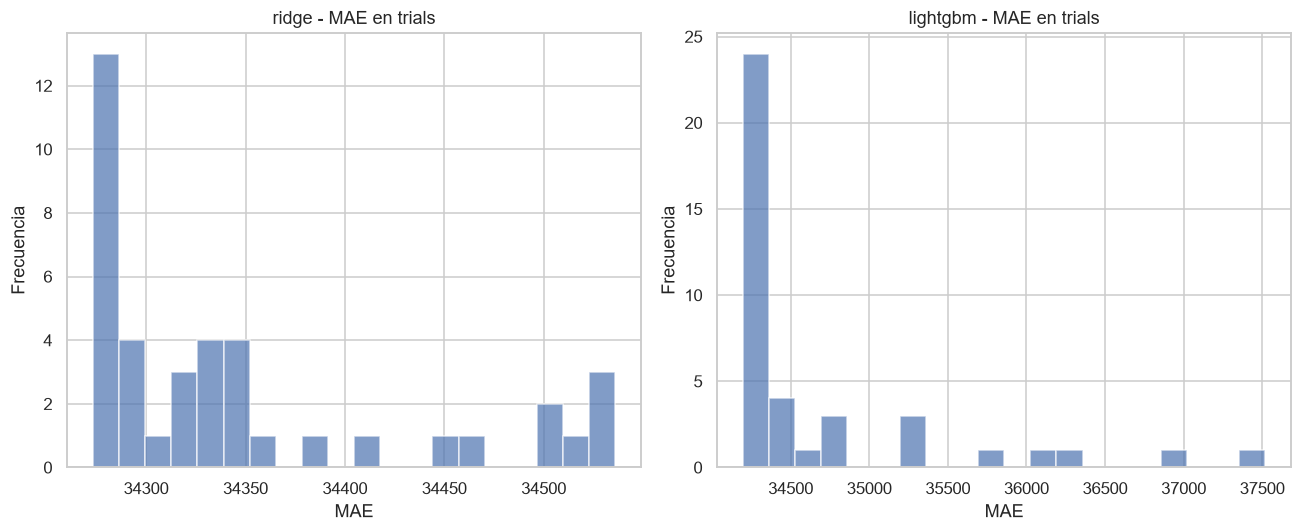

In [30]:
# Visualizar distribución de trials
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, model in enumerate(["ridge", "lightgbm"]):
    trials = optuna_trials[optuna_trials["model"] == model]
    axes[i].hist(trials["value"], bins=20, alpha=0.7, color=AZUL)
    axes[i].set_title(f"{model} - MAE en trials")
    axes[i].set_xlabel("MAE")
    axes[i].set_ylabel("Frecuencia")
plt.tight_layout()
guardar(fig, "3_optuna_trials")
plt.show()

---

In [31]:
print("Importancia de features (SHAP):")
print(feature_importance.head(15).to_string(index=False))

Importancia de features (SHAP):
               feature  mean_abs_shap   share_%  is_profile
Revenue_expanding_mean    1557.969861 10.559853       False
      AvgTicket_rmean7    1209.885805  8.200554       False
    DiscountShare_lag1    1144.273414  7.755836       False
  DiscountShare_rmean7    1061.526981  7.194984       False
         Revenue_lag14     907.721762  6.152499       False
       Revenue_rmean14     889.299366  6.027633       False
         NumSales_lag1     856.393467  5.804598       False
          Revenue_lag7     813.257352  5.512224       False
            WeekOfYear     664.521216  4.504096       False
           TenureYears     563.917457  3.822208        True
            DayOfMonth     554.117370  3.755784       False
        Revenue_rstd14     549.145274  3.722083       False
         Revenue_rstd7     538.361583  3.648992       False
        Revenue_rmean7     524.975053  3.558258       False
       Revenue_rmean28     461.938180  3.130997       False


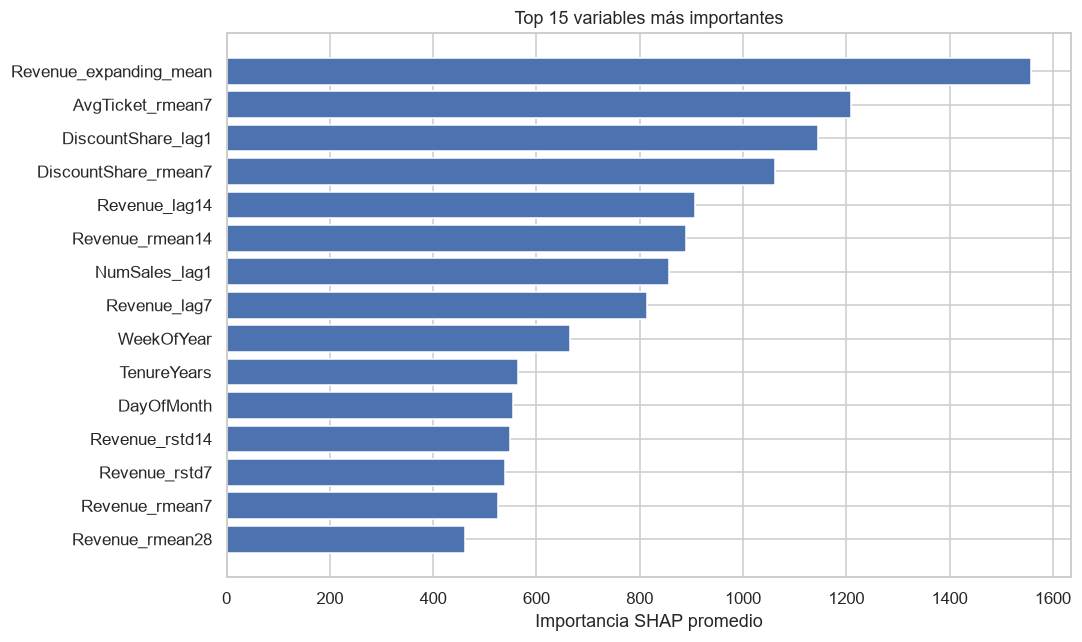

In [32]:
# Visualizar importancia
fig, ax = plt.subplots(figsize=(10, 6))
top_features = feature_importance.head(15)
ax.barh(top_features["feature"], top_features["mean_abs_shap"], color=AZUL)
ax.set_xlabel("Importancia SHAP promedio")
ax.set_title("Top 15 variables más importantes")
ax.invert_yaxis()
plt.tight_layout()
guardar(fig, "4_importancia_shap")
plt.show()

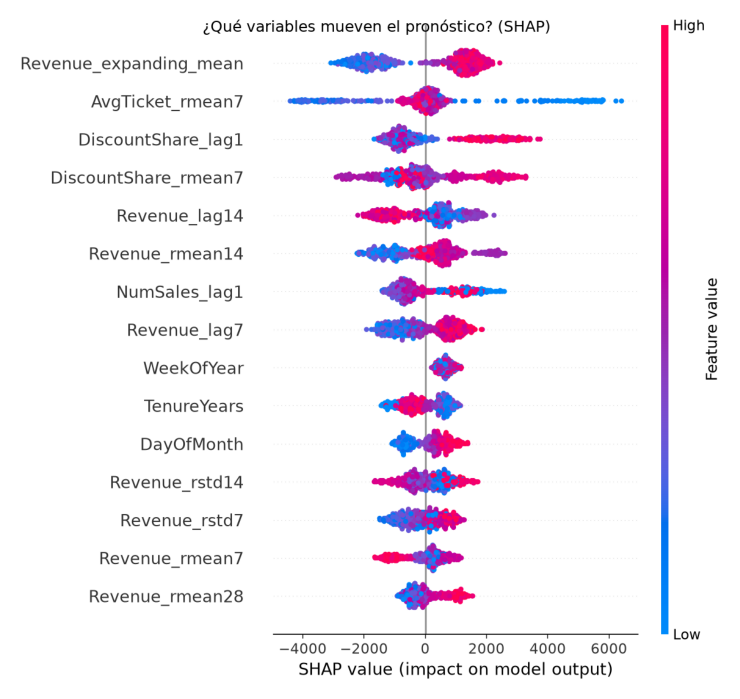

In [33]:
# Mostrar gráfico SHAP del pipeline (figura guardada por kedro run)
mostrar_png("shap_summary.png")

---

In [34]:
print("Resumen de vendedores:")
print(seller_summary.head().to_string(index=False))

Resumen de vendedores:
 SalesPersonID  Rank      Revenue  NumSales   Units  DiscountAmount  GrossRevenue  SharePct  AvgTicket  UnitsPerSale  DiscountPct  WeeklyTrendPct  VsTeamPct           Band    EmployeeName Gender  Age  TenureYears  AgeAtHire     CityName
            21     1 1.881669e+08    292024 3803313    5.767816e+06  1.939347e+08  4.386950 644.354155     13.023974     2.974102        0.068280   0.899841     Por encima    Devon Brewer      M 52.0          2.3       49.7    Baltimore
            20     2 1.875821e+08    290669 3781726    5.778294e+06  1.933604e+08  4.373315 645.345997     13.010421     2.988355       -0.065941   0.586255     Por encima   Shelby Riddle      M 53.9          5.1       48.8 Indianapolis
            13     3 1.874378e+08    290633 3785142    5.780396e+06  1.932182e+08  4.369951 644.929390     13.023786     2.991642       -0.023428   0.508872     Por encima    Katina Marks      M 55.1          6.4       48.7    Anchorage
             5     4 1.872717

In [35]:
print("\nInsights de ventas:")
print(json.dumps(sales_insights, indent=2, ensure_ascii=False))


Insights de ventas:
{
  "period": {
    "start": "2018-01-01",
    "end": "2018-05-09",
    "days": 129,
    "complete_weeks": 18
  },
  "totals": {
    "revenue": 4289241827.19,
    "sales": 6690599,
    "salespeople": 23,
    "avg_daily_revenue": 33249936.64,
    "daily_revenue_cv_pct": 0.55
  },
  "trend": {
    "weekly_slope_pct": 0.008,
    "first_week_revenue": 232895030.86,
    "last_week_revenue": 232711262.7,
    "weekday_anova_p": 0.8674
  },
  "salespeople": {
    "share_min_pct": 4.298,
    "share_max_pct": 4.387,
    "top_vs_bottom_gap_pct": 2.07,
    "anova_p_revenue": 1.7916482063405608e-07,
    "anova_p_num_sales": 0.3956995477234313,
    "anova_p_avg_ticket": 2.273764788458174e-18,
    "spearman_revenue_vs_ticket": 0.906,
    "spearman_revenue_vs_num_sales": 0.238,
    "bands": {
      "En el promedio": 18,
      "Por encima": 3,
      "Por debajo": 2
    },
    "growing": 14,
    "declining": 9
  },
  "discounts": {
    "discount_amount": 132468072.83,
    "discount_

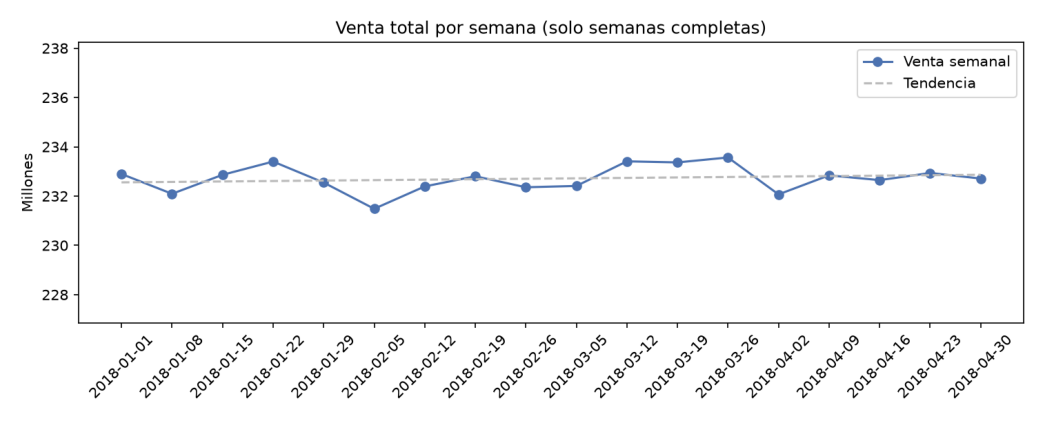

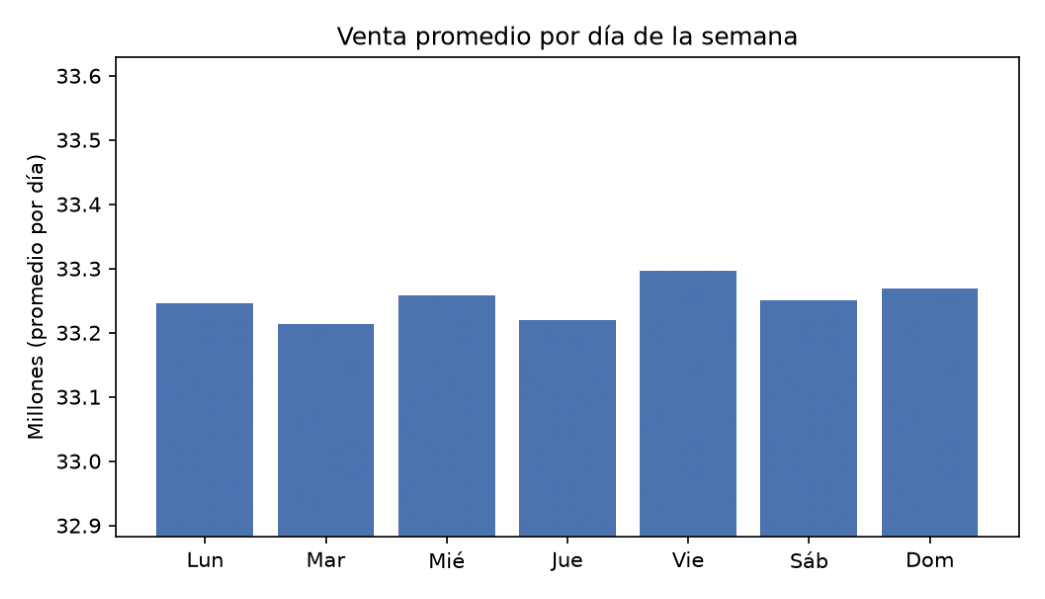

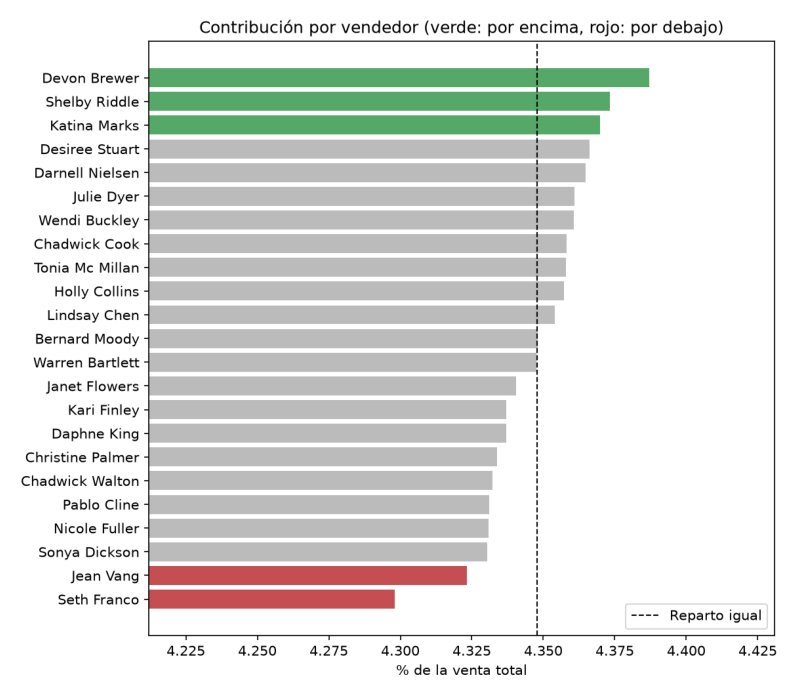

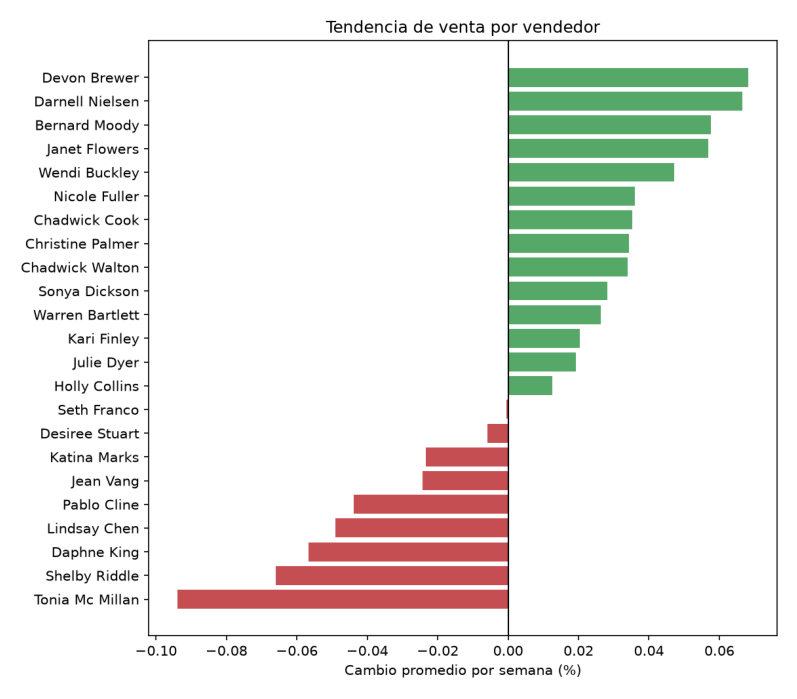

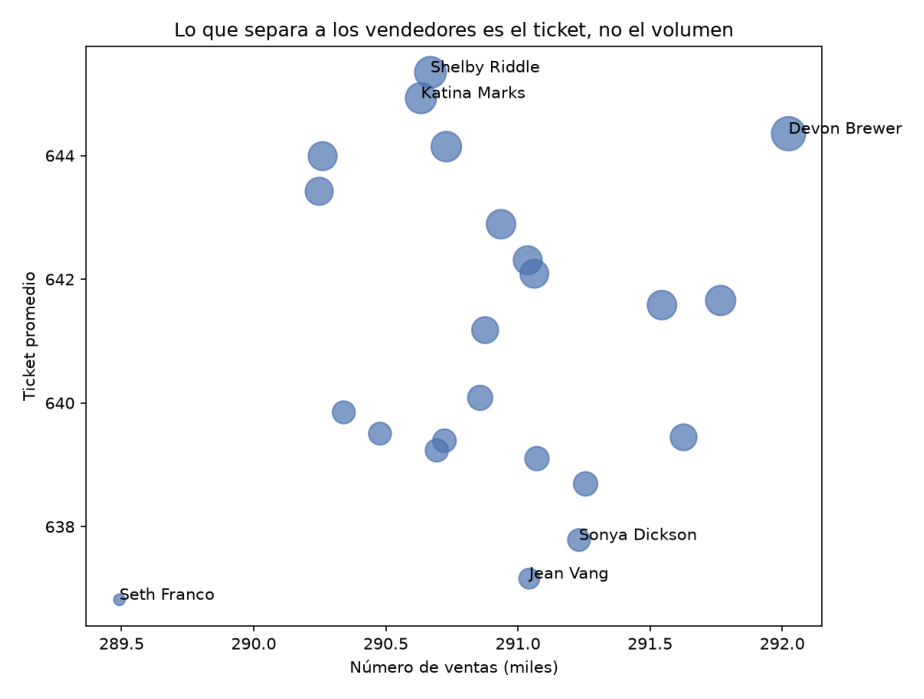

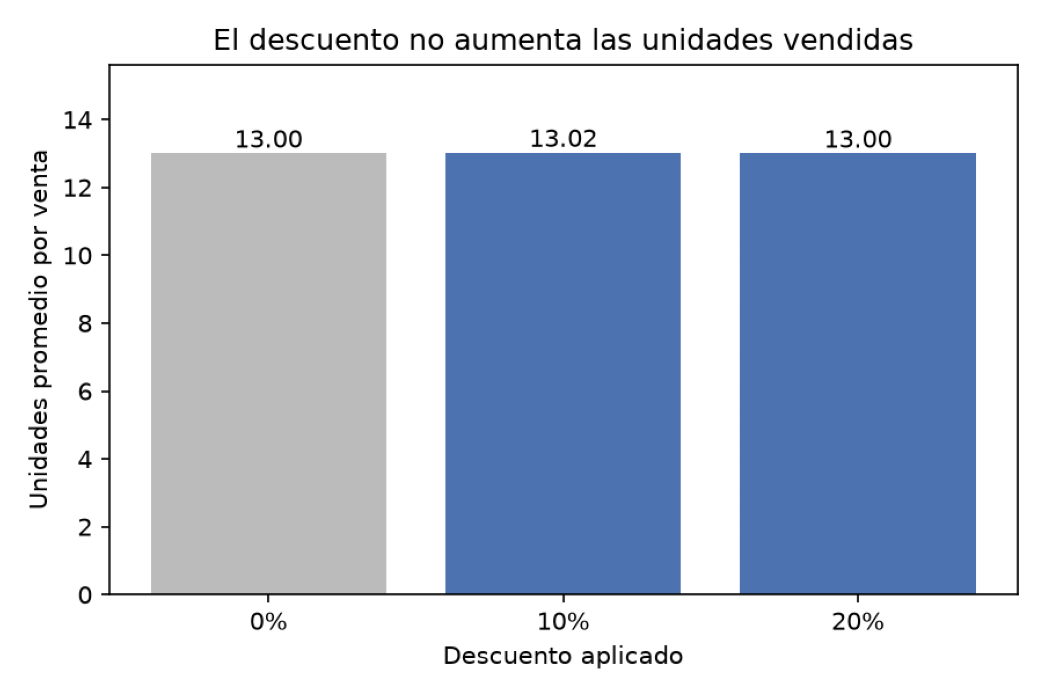

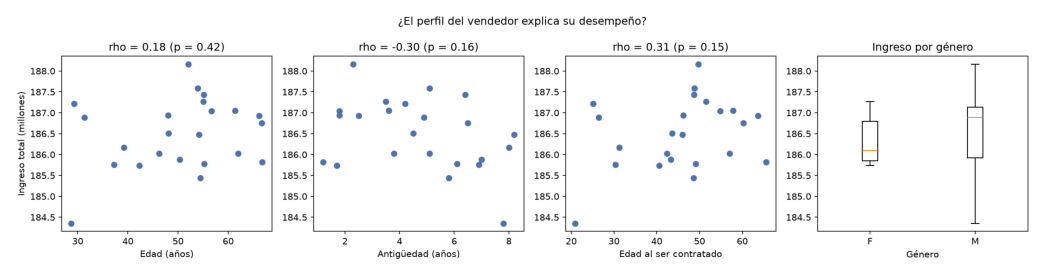

In [36]:
# Mostrar gráficos de análisis de ventas (figuras guardadas por kedro run)
for nombre in [
    "weekly_trend.png",
    "weekday_pattern.png",
    "seller_contribution.png",
    "seller_trend.png",
    "volume_vs_ticket.png",
    "discount_effect.png",
    "profile_vs_performance.png",
]:
    mostrar_png(nombre)

---

In [37]:
print("Impacto de negocio:")
print(json.dumps(business_impact, indent=2, ensure_ascii=False))

Impacto de negocio:
{
  "discounts": {
    "discount_given_period": 132468072.83,
    "discount_given_annual": 374812764.21,
    "units_per_sale_by_discount": {
      "0%": 13.0,
      "10%": 13.02,
      "20%": 13.0
    },
    "scenarios": [
      {
        "reduction_pct": 25.0,
        "recovered_period": 33117018.21,
        "recovered_annual": 93703191.05,
        "revenue_increase_pct": 0.77
      },
      {
        "reduction_pct": 50.0,
        "recovered_period": 66234036.41,
        "recovered_annual": 187406382.1,
        "revenue_increase_pct": 1.54
      },
      {
        "reduction_pct": 100.0,
        "recovered_period": 132468072.83,
        "recovered_annual": 374812764.21,
        "revenue_increase_pct": 3.09
      }
    ],
    "assumption": "Las unidades por venta no cambian al reducir el descuento (en los datos son iguales con 0%, 10% y 20%). No se puede medir si algún cliente dejaría de comprar."
  },
  "upselling": {
    "high_value_price_threshold": 75.25,
    "

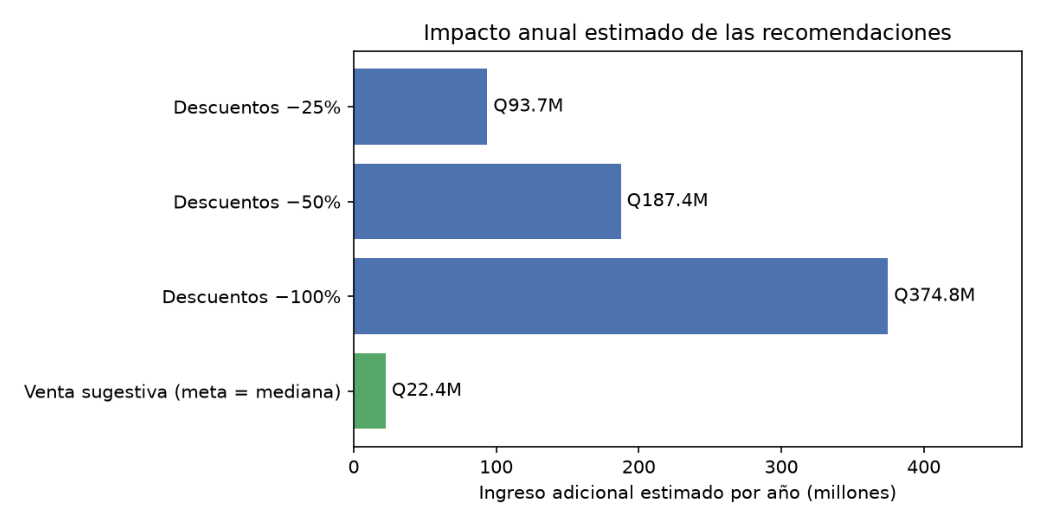

In [38]:
# Mostrar gráfico de impacto (figura guardada por kedro run)
mostrar_png("business_impact.png")

In [39]:
# Cargar upsell por vendedor
upsell = catalog.load("upsell_by_seller")
print("Venta sugestiva por vendedor:")
print(upsell.to_string(index=False))

Venta sugestiva por vendedor:
 SalesPersonID  HighValueSales  UnitsPerSale  Units      Revenue  RevenuePerUnit  UnitGap  UpliftPeriod  UpliftAnnual
            17           72174     12.808657 924452 7.784528e+07       84.206948 0.201502  1.224639e+06  3.465065e+06
            10           72771     12.822484 933105 7.859332e+07       84.227729 0.187675  1.150321e+06  3.254785e+06
             2           72716     12.838990 933600 7.874605e+07       84.346668 0.171169  1.049839e+06  2.970475e+06
             9           72797     12.864926 936528 7.890798e+07       84.255871 0.145233  8.907985e+05  2.520477e+06
            18           72593     12.896051 936163 7.894401e+07       84.327206 0.114108  6.985217e+05  1.976437e+06
             1           72650     12.903097 937410 7.896801e+07       84.240628 0.107062  6.552275e+05  1.853938e+06
             3           72925     12.917216 941988 7.939702e+07       84.286655 0.092943  5.712815e+05  1.616417e+06
            16           7

---

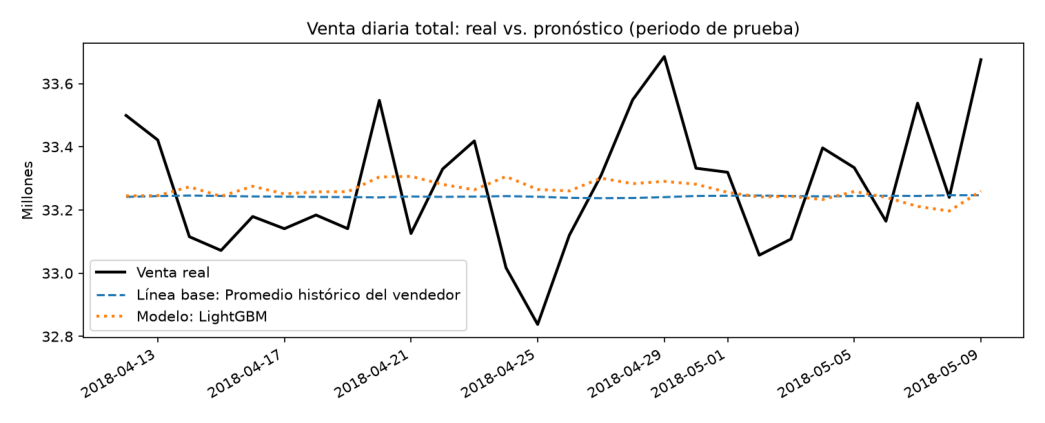

In [40]:
# Mostrar gráfico de forecast vs actual (figura guardada por kedro run)
mostrar_png("forecast_vs_actual.png")

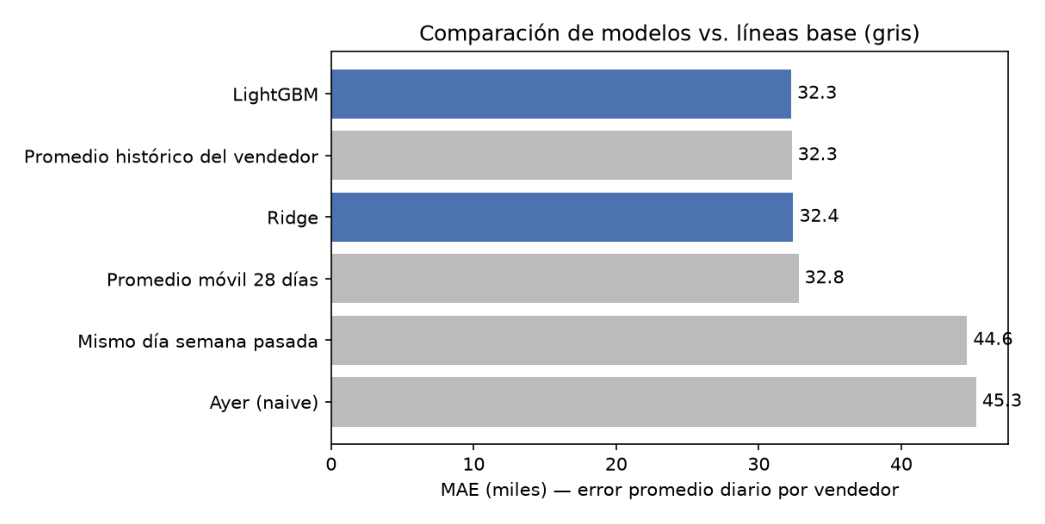

In [41]:
# Mostrar gráfico de comparación de modelos (figura guardada por kedro run)
mostrar_png("model_comparison.png")

---

In [43]:
summary = {
    "selected_model": model_selection["selected_model"],
    "best_baseline_mae": model_selection["best_baseline_mae"],
    "best_ml_mae": model_selection["best_ml_mae"],
    "ml_improvement_%": model_selection["ml_improvement_%"],
    "reason": model_selection["reason"],
    "top_features": feature_importance.head(5)["feature"].tolist(),
    "business_impact": business_impact,
}

with open("resultados_resumen.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)